# Data Exploration
Inspect raw sensor data quality, distributions, and relationships before defining preprocessing and target variables.

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW_DATA_DIR = Path('../data/raw')
csv_files = sorted(RAW_DATA_DIR.glob('*.csv'))
csv_files

[WindowsPath('../data/raw/irrigation_prediction.csv')]

In [6]:
if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {RAW_DATA_DIR.resolve()}"
    )

# Select the first CSV file
file_path = csv_files[0]

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

print("File loaded:", file_path.name)
print("Dataset loaded successfully!")

File loaded: irrigation_prediction.csv
Dataset loaded successfully!


In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 10000
Number of columns: 20

Column names:
['Soil_Type', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Field_Area_hectare', 'Mulching_Used', 'Previous_Irrigation_mm', 'Region', 'Irrigation_Need']


In [8]:
display(df.head())

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium


In [9]:
display(df.tail())

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
9995,Silt,7.01,26.67,0.86,0.76,27.61,52.20,1075.12,7.41,19.66,Sugarcane,Sowing,Kharif,Drip,Groundwater,2.62,Yes,92.44,South,Low
9996,Clay,5.40,49.44,0.90,1.19,34.03,52.31,1591.84,9.86,5.66,Maize,Sowing,Kharif,Rainfed,Groundwater,4.87,No,15.46,South,Low
9997,Loamy,4.97,60.63,0.99,1.30,36.68,68.16,2384.87,10.75,13.40,Potato,Harvest,Kharif,Canal,Groundwater,10.08,Yes,116.36,North,Low
9998,Loamy,7.12,44.33,1.56,1.08,31.50,64.83,2397.01,4.03,3.05,Sugarcane,Harvest,Kharif,Rainfed,Reservoir,11.11,Yes,118.17,East,Low
9999,Sandy,5.65,62.25,1.48,3.00,35.71,45.33,177.69,10.93,12.32,Potato,Harvest,Kharif,Canal,Rainwater,11.32,No,98.88,North,Medium


In [12]:
#inspecting data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Soil_Type                10000 non-null  str    
 1   Soil_pH                  10000 non-null  float64
 2   Soil_Moisture            10000 non-null  float64
 3   Organic_Carbon           10000 non-null  float64
 4   Electrical_Conductivity  10000 non-null  float64
 5   Temperature_C            10000 non-null  float64
 6   Humidity                 10000 non-null  float64
 7   Rainfall_mm              10000 non-null  float64
 8   Sunlight_Hours           10000 non-null  float64
 9   Wind_Speed_kmh           10000 non-null  float64
 10  Crop_Type                10000 non-null  str    
 11  Crop_Growth_Stage        10000 non-null  str    
 12  Season                   10000 non-null  str    
 13  Irrigation_Type          10000 non-null  str    
 14  Water_Source             10000 non

In [ ]:
#finding missing values and its percentage
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        by="Missing_Count",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Soil_Type,0,0.0
Soil_pH,0,0.0
Soil_Moisture,0,0.0
Organic_Carbon,0,0.0
Electrical_Conductivity,0,0.0
Temperature_C,0,0.0
Humidity,0,0.0
Rainfall_mm,0,0.0
Sunlight_Hours,0,0.0
Wind_Speed_kmh,0,0.0


In [ ]:
#This summarizes numerical columns, including their minimum, maximum, mean, and median.
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Soil_pH,10000.0,6.487857,0.979963,4.80,5.640,6.470,7.3500,8.20
Soil_Moisture,10000.0,36.969207,16.430845,8.00,22.860,37.240,50.9400,65.00
Organic_Carbon,10000.0,0.944731,0.372406,0.30,0.620,0.950,1.2600,1.60
Electrical_Conductivity,10000.0,1.791963,0.984202,0.10,0.940,1.780,2.6500,3.50
Temperature_C,10000.0,26.991423,8.664074,12.00,19.460,27.090,34.5000,42.00
Humidity,10000.0,60.080339,20.187973,25.00,42.855,60.040,77.7050,95.00
Rainfall_mm,10000.0,1252.499420,715.582201,0.38,634.155,1250.335,1880.2650,2499.69
Sunlight_Hours,10000.0,7.518538,2.016077,4.00,5.760,7.560,9.2600,11.00
Wind_Speed_kmh,10000.0,10.163545,5.670923,0.50,5.160,10.190,15.1000,20.00
Field_Area_hectare,10000.0,7.598024,4.233919,0.30,3.950,7.540,11.2025,15.00


In [15]:
#This summarizes numerical columns, including their minimum, maximum, mean, and median.
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Soil_Type,10000,4,Sandy,2536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_pH,10000.0,NaN,NaN,NaN,6.487857,0.979963,4.8,5.64,6.47,7.35,8.2
Soil_Moisture,10000.0,NaN,NaN,NaN,36.969207,16.430845,8.0,22.86,37.24,50.94,65.0
Organic_Carbon,10000.0,NaN,NaN,NaN,0.944731,0.372406,0.3,0.62,0.95,1.26,1.6
Electrical_Conductivity,10000.0,NaN,NaN,NaN,1.791963,0.984202,0.1,0.94,1.78,2.65,3.5
Temperature_C,10000.0,NaN,NaN,NaN,26.991423,8.664074,12.0,19.46,27.09,34.5,42.0
Humidity,10000.0,NaN,NaN,NaN,60.080339,20.187973,25.0,42.855,60.04,77.705,95.0
Rainfall_mm,10000.0,NaN,NaN,NaN,1252.49942,715.582201,0.38,634.155,1250.335,1880.265,2499.69
Sunlight_Hours,10000.0,NaN,NaN,NaN,7.518538,2.016077,4.0,5.76,7.56,9.26,11.0
Wind_Speed_kmh,10000.0,NaN,NaN,NaN,10.163545,5.670923,0.5,5.16,10.19,15.1,20.0


In [16]:
#check for duplicates
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 0


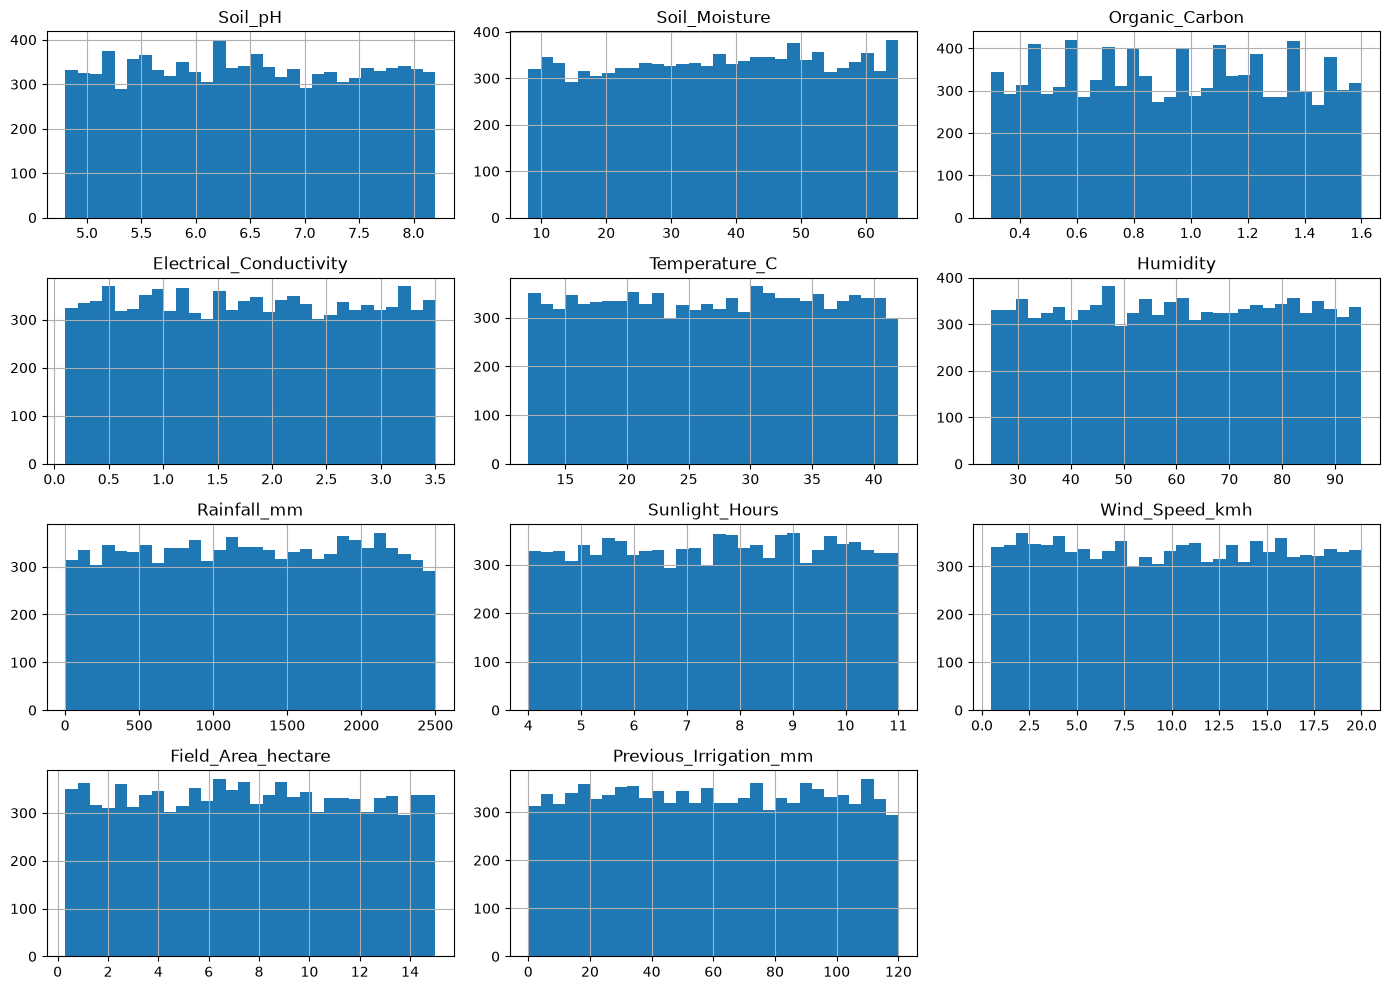

In [17]:
#visualizing numerical features
numeric_columns = df.select_dtypes(
    include="number"
).columns

df[numeric_columns].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

In [3]:
%pip install matplotlib seaborn

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19
   ------------ --------------------------- 0.8/2.5 MB 22.1 kB/s eta 0:01:19

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Choose the appropriate file after placing a dataset in data/raw/.
if not csv_files:
    raise FileNotFoundError('Add a CSV dataset to data/raw/ before continuing.')
data = pd.read_csv(csv_files[0])
display(data.head())
data.info()

In [ ]:
display(data.describe(include='all').T)
display(data.isna().sum().sort_values(ascending=False).to_frame('missing_values'))
numeric_data = data.select_dtypes(include='number')
if not numeric_data.empty:
    sns.heatmap(numeric_data.corr(), cmap='vlag', center=0)
    plt.title('Sensor feature correlations')
    plt.tight_layout()
    plt.show()

In [19]:
#my target variable is irrigation_need and i need to determine how frequently each class occurs
target_counts = df["Irrigation_Need"].value_counts()

print("Class counts:")
display(target_counts.to_frame("Count"))

print("Class percentages:")
display(
    (df["Irrigation_Need"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Class counts:


,Count
Irrigation_Need,
Low,5864
Medium,3800
High,336


Class percentages:


,Percentage
Irrigation_Need,
Low,58.64
Medium,38.00
High,3.36


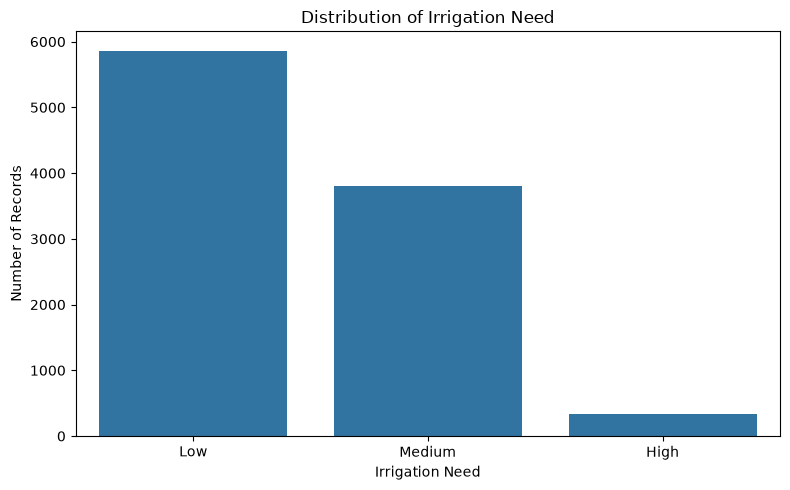

In [ ]:
#visualize the distribution
#i need to know if low medium and high are reasonably represented , if one class is rare , i'll account for that when training and evaluating the model 
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Irrigation_Need")

plt.title("Distribution of Irrigation Need")
plt.xlabel("Irrigation Need")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [21]:
#inspect the categorical features,checking for inconsistent spelling or capitalization , unexpected categories , empty strings that may not be detected as missing values , categories that may occur very rarely
categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False))


--- Soil_Type ---
Unique values: 4
Soil_Type
Sandy    2536
Silt     2501
Loamy    2486
Clay     2477
Name: count, dtype: int64

--- Crop_Type ---
Unique values: 6
Crop_Type
Rice         1711
Maize        1694
Sugarcane    1678
Potato       1663
Wheat        1659
Cotton       1595
Name: count, dtype: int64

--- Crop_Growth_Stage ---
Unique values: 4
Crop_Growth_Stage
Harvest       2581
Vegetative    2521
Flowering     2465
Sowing        2433
Name: count, dtype: int64

--- Season ---
Unique values: 3
Season
Rabi      3383
Kharif    3362
Zaid      3255
Name: count, dtype: int64

--- Irrigation_Type ---
Unique values: 4
Irrigation_Type
Sprinkler    2527
Rainfed      2511
Drip         2495
Canal        2467
Name: count, dtype: int64

--- Water_Source ---
Unique values: 4
Water_Source
River          2528
Reservoir      2513
Rainwater      2497
Groundwater    2462
Name: count, dtype: int64

--- Mulching_Used ---
Unique values: 2
Mulching_Used
No     5013
Yes    4987
Name: count, dtype: int64

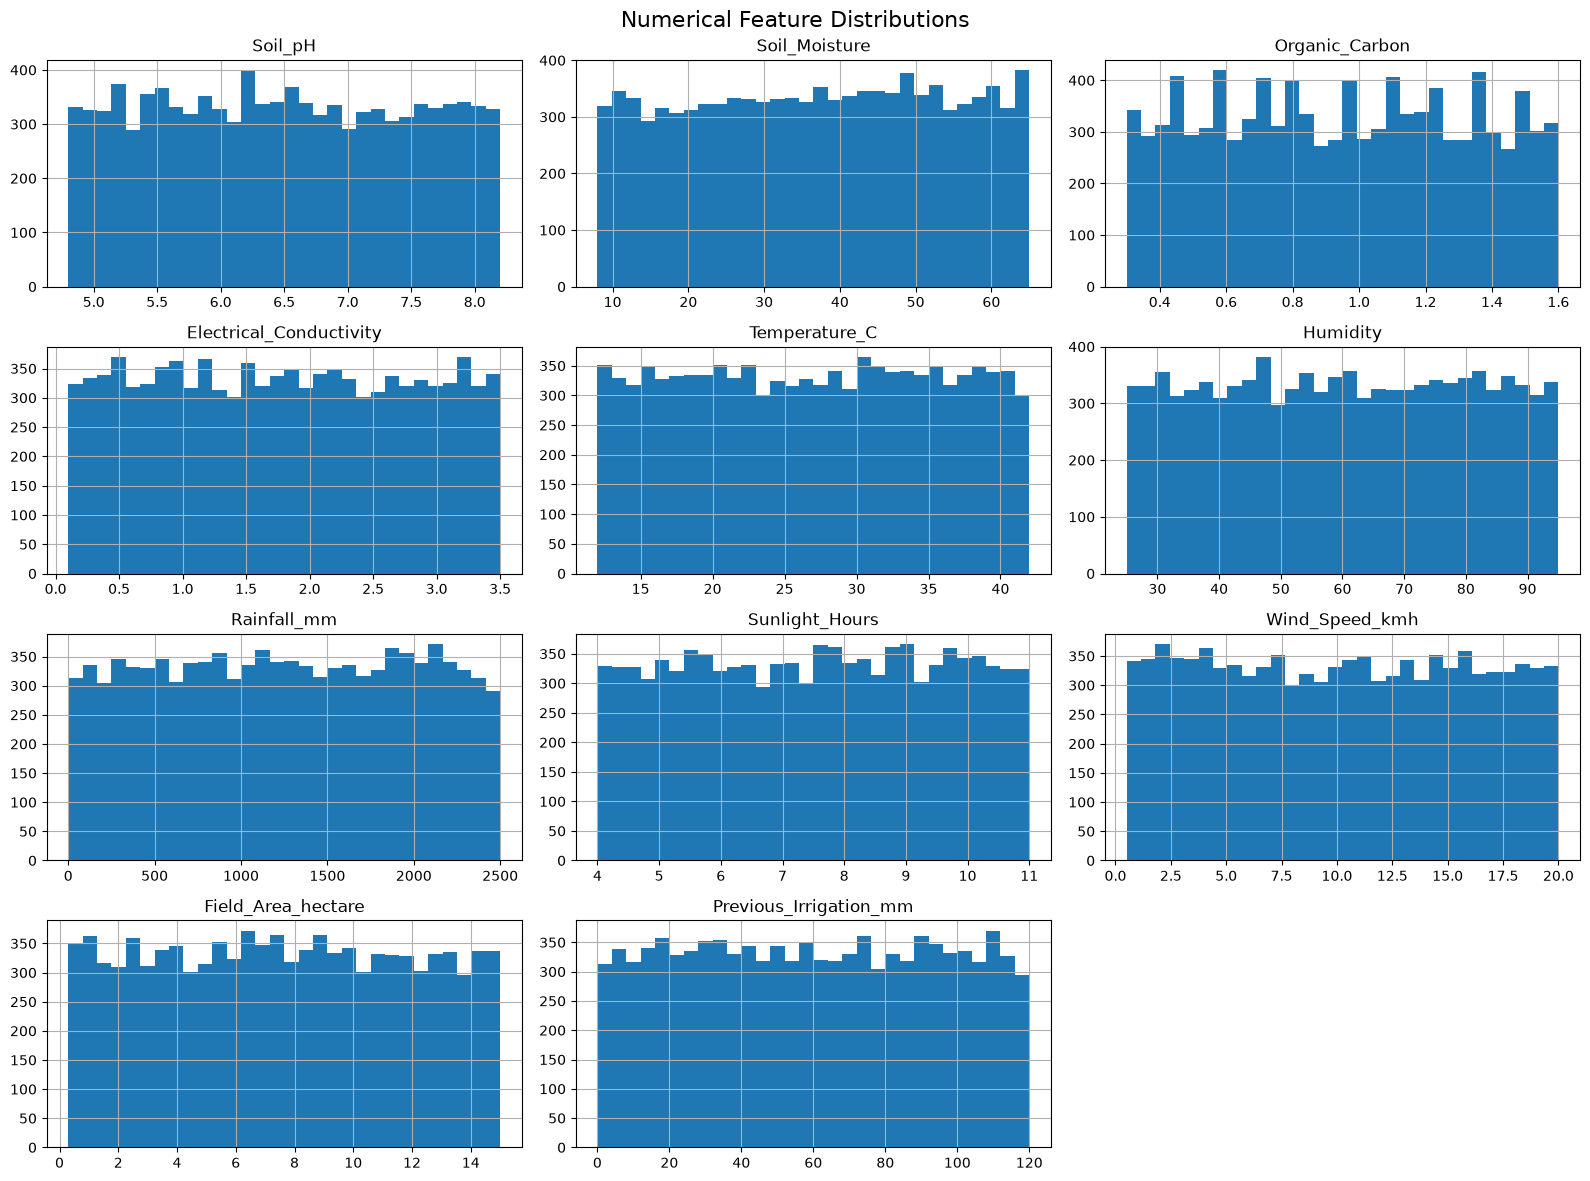

In [23]:
#histogram help reveal skewed distributions, unusual spikes and potential outliers
df[numeric_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle(
    "Numerical Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
#check invalid numerical values
checks = {
    "Soil pH outside 0-14": (
        (df["Soil_pH"] < 0) |
        (df["Soil_pH"] > 14)
    ).sum(),

    "Humidity outside 0-100": (
        (df["Humidity"] < 0) |
        (df["Humidity"] > 100)
    ).sum(),

    "Negative soil moisture": (
        df["Soil_Moisture"] < 0
    ).sum(),

    "Negative rainfall": (
        df["Rainfall_mm"] < 0
    ).sum(),

    "Non-positive field area": (
        df["Field_Area_hectare"] <= 0
    ).sum(),

    "Negative wind speed": (
        df["Wind_Speed_kmh"] < 0
    ).sum()
}

display(
    pd.Series(checks, name="Invalid_Count").to_frame()
)

,Invalid_Count
Soil pH outside 0-14,0
Humidity outside 0-100,0
Negative soil moisture,0
Negative rainfall,0
Non-positive field area,0
Negative wind speed,0


: 